# SMART goal checker — 5 small ML models

A goal is **SMART** when it is:

| Letter | Criterion | What the model looks for |
|---|---|---|
| **S** | Specific | a concrete action/outcome, not "get better" or "be successful" |
| **M** | Measurable | a quantified target (number, %, amount) |
| **A** | Achievable | the target is realistic for its scale and time frame |
| **R** | Relevant | the goal says *why* it matters / what bigger objective it serves |
| **T** | Time-bound | a concrete deadline or time window |

Each criterion gets its **own independent classifier** (a decision tree), so a
goal gets 5 yes/no answers with a probability each.

**Plan**
1. Generate a labelled synthetic dataset (no public SMART dataset exists).
2. Turn text into features: hand-crafted regex features + TF-IDF words.
3. Train 5 decision trees, compare them with logistic regression and random forest.
4. Look inside the trees (rules, feature importances).
5. Test on hand-written goals that the generator never produced.
6. `check_goal("...")` — try your own.

> ⚠️ Honest caveat: *Achievable* and *Relevant* are really judgement calls that
> depend on the person and context. Here they're approximated by text cues
> (absurd amounts / impossible phrasing; a stated reason). The models learn
> those cues — not common sense.

In [1]:
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import MaxAbsScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

SEED = 42
CRITERIA = ["specific", "measurable", "achievable", "relevant", "time_bound"]
pd.set_option("display.max_colwidth", 140)

## 1. Synthetic dataset

Every goal is assembled from parts. For each of the 5 criteria we flip a coin
and pick a phrase that satisfies it or not, so **labels are independent** and
known by construction:

- **S** — a concrete domain action (*"build an emergency fund"*) vs. a vague one (*"get my life together"*)
- **M** — a quantified target (*"save $3,000"*) vs. none
- **A** — a realistic number vs. an absurd one (*"lose 60 kg"*), an absurdly short deadline (*"by tomorrow"*), or impossible phrasing (*"overnight"*)
- **R** — a reason tied to the domain vs. no reason or a throw-away one (*"just because"*)
- **T** — a deadline (*"within 3 months"*) vs. none or a non-deadline (*"someday"*)

Then: random sentence starters, sometimes the deadline moves to the front,
and 3% of labels are flipped to simulate annotator noise.

In [2]:
# Each domain: concrete actions without numbers, and measured templates with
# (realistic values, unrealistic values), plus domain-relevant reasons.
DOMAINS = {
    "running": dict(
        specific=["start running regularly before work", "train for my first running race",
                  "build a habit of jogging in the park"],
        measured=[("run {n} km without stopping", [5, 10, 15], [150, 300, 500]),
                  ("finish a {n} km race", [5, 10, 21], [400, 1000])],
        reasons=["so I can join the company running team", "to improve my heart health as my doctor advised",
                 "because I want to take part in the city marathon next year"],
    ),
    "weight": dict(
        specific=["cut sugar out of my diet", "cook healthy meals at home instead of ordering takeout",
                  "replace snacks with fruit and vegetables"],
        measured=[("lose {n} kg", [3, 5, 8], [40, 60, 90]),
                  ("cook at home {n} days a week", [3, 4, 5], [9, 12, 15])],
        reasons=["so that my blood pressure goes back to normal", "to feel confident at my sister's wedding",
                 "because my doctor said it will reduce my diabetes risk"],
    ),
    "language": dict(
        specific=["take weekly Spanish lessons with a tutor", "practice Spanish conversation with native speakers",
                  "study Spanish grammar with an app"],
        measured=[("learn {n} new Spanish words", [300, 500, 800], [50000, 100000]),
                  ("hold a {n}-minute conversation in Spanish", [10, 15, 30], [900, 2000])],
        reasons=["because I am relocating to Madrid for work", "so I can talk to my partner's family",
                 "to qualify for the international sales role"],
    ),
    "career": dict(
        specific=["get promoted to senior data analyst", "move into a team lead role",
                  "ask my manager for a formal performance review"],
        measured=[("increase my salary by {n}%", [10, 15, 20], [300, 500, 900]),
                  ("complete {n} professional certifications", [1, 2, 3], [25, 40])],
        reasons=["to support my family's plan to buy a house", "so that I can lead the analytics team",
                 "because it is the next step in my five-year career plan"],
    ),
    "sales": dict(
        specific=["launch a referral program for our customers", "grow sales of our online store",
                  "redesign the checkout page of our web shop"],
        measured=[("increase monthly revenue by {n}%", [10, 15, 25], [800, 2000, 5000]),
                  ("sign {n} new enterprise clients", [3, 5, 10], [500, 2000])],
        reasons=["to hit the company's annual revenue target", "so we can afford to hire two more engineers",
                 "because investors expect growth before the next funding round"],
    ),
    "savings": dict(
        specific=["build an emergency fund", "pay off my credit card debt",
                  "set up an automatic transfer to my savings account"],
        measured=[("save ${n:,}", [1000, 3000, 5000], [5000000, 20000000]),
                  ("pay off ${n:,} of debt", [2000, 4000, 6000], [3000000, 9000000])],
        reasons=["so that I have a safety net if I lose my job", "to cover a down payment on an apartment",
                 "because I want to stop paying high interest every month"],
    ),
    "reading": dict(
        specific=["read classic novels before bed", "join a book club at the local library",
                  "replace evening scrolling with reading"],
        measured=[("read {n} books", [12, 20, 24], [600, 1500]),
                  ("read {n} pages a day", [10, 20, 30], [2000, 5000])],
        reasons=["to improve my writing for my journalism course", "so I can discuss books with my kids",
                 "because reading helps me sleep better"],
    ),
    "coding": dict(
        specific=["learn Python for data analysis", "build a personal portfolio website",
                  "contribute to an open-source project"],
        measured=[("complete {n} Python projects", [3, 5, 6], [300, 800]),
                  ("solve {n} coding challenges", [50, 100, 150], [40000, 90000])],
        reasons=["so I can switch to a data engineering job", "to prepare for technical interviews",
                 "because my team is moving its tooling to Python"],
    ),
}

VAGUE = ["get better", "improve myself", "be more successful", "do better at work", "be healthier",
         "make things better", "work on my personal growth", "be happier", "get my life together",
         "achieve great things", "get fit", "be more organized", "make more money", "be a better leader",
         "eat better", "level up my career", "be more confident", "focus on what matters"]
VAGUE_MEASURED = [("improve myself by {n}%", [10, 20], [900, 5000]),
                  ("be {n}% more productive", [10, 15, 25], [700, 3000]),
                  ("make things {n}% better", [10, 20], [1000, 9000]),
                  ("be {n} times more confident", [2, 3], [100, 1000])]

SUPPORT = ["", "", "with help from a mentor", "by practicing a little every day",
           "following a step-by-step plan", "by setting aside time each week"]
IMPOSSIBLE = ["overnight", "without putting in any effort", "and become the best in the world at it",
              "while working on it only once a year", "without spending any time or money"]

DEADLINES = ["by December 2026", "by the end of 2026", "within 3 months", "within six weeks",
             "by 30 June 2027", "before the end of Q2", "in the next 90 days", "by my birthday in March",
             "by the end of this year", "within 12 months", "by the end of this quarter", "in 8 weeks",
             "in four months", "before the end of next year", "by next spring"]
ABSURD_DEADLINES = ["by tomorrow", "in the next 2 days", "by tonight", "within 24 hours"]
NO_DEADLINE = ["", "", "", "someday", "eventually", "soon", "one day", "in the future",
               "when I have time", "at some point"]

GENERIC_REASONS = ["because it supports my long-term plan", "so that I can grow professionally"]
WEAK_REASONS = ["", "", "", "just because", "because everyone else is doing it", "for no real reason",
                "because I saw it on TikTok", "because why not"]

STARTERS = ["I will", "I want to", "My goal is to", "I'm going to", "I plan to", "I aim to"]
FRONTABLE = re.compile(r"^(by|within|in the next|before)\b")


def make_goal(rng: random.Random) -> dict:
    labels = {c: rng.random() < 0.5 for c in CRITERIA}
    S, M, A, R, T = (labels[c] for c in CRITERIA)
    domain = DOMAINS[rng.choice(list(DOMAINS))]

    # time-bound part
    time_phrase = rng.choice(DEADLINES) if T else rng.choice(NO_DEADLINE)

    # specific + measurable + achievable parts
    extra = ""
    if M:
        template, ok_values, crazy_values = rng.choice(domain["measured"] if S else VAGUE_MEASURED)
        if A:
            n = rng.choice(ok_values)
        elif T and rng.random() < 0.4:      # realistic size, impossible deadline
            n, time_phrase = rng.choice(ok_values), rng.choice(ABSURD_DEADLINES)
        else:
            n = rng.choice(crazy_values)
        core = template.format(n=n)
    else:
        core = rng.choice(domain["specific"]) if S else rng.choice(VAGUE)
        extra = rng.choice(SUPPORT) if A else rng.choice(IMPOSSIBLE)

    # relevant part
    reason = rng.choice(domain["reasons"] + GENERIC_REASONS) if R else rng.choice(WEAK_REASONS)

    starter = rng.choice(STARTERS) if rng.random() < 0.8 else ""
    if time_phrase and FRONTABLE.match(time_phrase) and rng.random() < 0.3:
        lead = time_phrase[0].upper() + time_phrase[1:]
        starter = starter if starter.startswith("I") else starter[:1].lower() + starter[1:]
        parts = [f"{lead}, {starter}".rstrip(), core, extra, reason]
    else:
        parts = [starter, core, extra, time_phrase, reason]
    text = " ".join(p for p in parts if p)
    text = text[0].upper() + text[1:] + rng.choice([".", ".", "", "!"])
    return {"text": text, **{c: int(v) for c, v in labels.items()}}


def make_dataset(n: int, noise: float = 0.03, seed: int = SEED) -> pd.DataFrame:
    rng = random.Random(seed)
    df = pd.DataFrame([make_goal(rng) for _ in range(n)]).drop_duplicates("text").reset_index(drop=True)
    flip = np.random.default_rng(seed).random((len(df), len(CRITERIA))) < noise
    df[CRITERIA] = np.where(flip, 1 - df[CRITERIA].values, df[CRITERIA].values)
    return df


df = make_dataset(6000)
print(f"{len(df)} unique goals")
df.sample(10, random_state=1)

5988 unique goals


,text,specific,measurable,achievable,relevant,time_bound
5786,Be more confident by setting aside time each week within 3 months just because.,0,0,1,0,1
1586,I plan to level up my career so that I can grow professionally.,0,0,1,1,0
2632,My goal is to read 2000 pages a day eventually because why not.,0,1,0,0,0
2950,I plan to be 700% more productive by 30 June 2027 for no real reason!,0,1,0,0,1
496,I plan to be more successful with help from a mentor to feel confident at my sister's wedding!,0,0,1,1,0
5321,I will move into a team lead role with help from a mentor when I have time because it is the next step in my five-year career plan!,1,0,1,1,0
354,I'm going to increase my salary by 10% because why not,1,1,1,0,0
503,My goal is to improve myself by 20% before the end of Q2 because I saw it on TikTok!,0,1,1,0,1
4071,I aim to lose 3 kg one day because my doctor said it will reduce my diabetes risk,1,1,1,1,0
4879,I want to complete 3 Python projects in 8 weeks because why not.,1,1,0,0,1


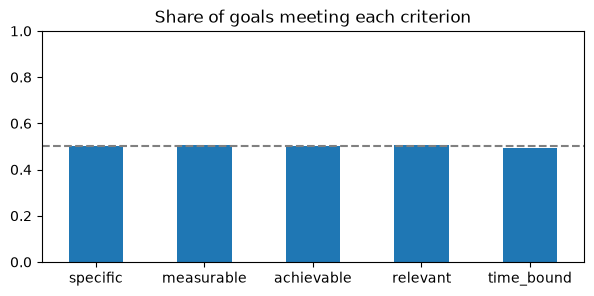

In [3]:
ax = df[CRITERIA].mean().plot.bar(title="Share of goals meeting each criterion", ylim=(0, 1), rot=0, figsize=(7, 3))
ax.axhline(0.5, ls="--", c="grey")
plt.show()

## 2. Features

Two feature groups glued together with a `FeatureUnion`:

1. **Hand-crafted features** (`SmartFeatures`) — numbers that describe the
   text. Dates and durations are masked *before* counting target numbers, so
   "within 3 months" doesn't make a goal look measurable. A unit-aware check
   flags oversized quantities (500 km, $20,000,000, 12 days a week...).
2. **TF-IDF** of words and word pairs — lets the trees pick up phrases we
   didn't think of.

In [4]:
MONTHS = r"(?:january|february|march|april|may|june|july|august|september|october|november|december)"
TIME_TOKEN = re.compile(
    rf"\b\d+\s*(?:hours?|days?|weeks?|months?|years?)\b(?!\s+a\s+week)"   # durations (not '5 days a week')
    rf"|\b(?:19|20)\d{{2}}\b|\b\d{{1,2}}(?:st|nd|rd|th)?\s+{MONTHS}\b|\b{MONTHS}\s+\d{{1,2}}\b|\bq[1-4]\b",
    re.I)
NUMBER = re.compile(r"\d[\d,]*(?:\.\d+)?")
QUANTITY = re.compile(r"(\$)?\s?(\d[\d,]*)\s*(%|km|kg|books|pages|words|clients|projects|certifications|"
                      r"challenges|-minute|minutes|days a week|times|followers|languages)?", re.I)
# above these values a target looks unrealistic
EXTREME = {"%": 200, "km": 100, "kg": 30, "books": 200, "pages": 500, "words": 20000, "clients": 200,
           "projects": 100, "certifications": 10, "challenges": 10000, "-minute": 300, "minutes": 300,
           "days a week": 7, "times": 50, "followers": 5000, "languages": 4, "$": 1_000_000}

PATTERNS = {
    # 'by'/'before'/'until' only count when followed by something date-like
    # (so 'by 10%' and 'by practicing' don't look like deadlines)
    "has_deadline": (rf"\b(by|before|until)\s+(the end of|end of|my birthday|tomorrow|tonight|next|this|"
                     rf"\d|q[1-4]\b|{MONTHS})|\b(within|in the next|in)\s+(\d+|a|one|two|three|four|five|six|eight|ten|twelve)\s+"
                     rf"(hours?|days?|weeks?|months?|years?)\b|"
                     rf"\bthis (quarter|year|month|week)\b|\bdeadline\b"),
    "has_month": rf"\b{MONTHS}\b",
    "has_year": r"\b(19|20)\d{2}\b",
    "has_duration": r"\b\d+\s*(hours?|days?|weeks?|months?|years?)\b|\b(six|three|two|twelve) (weeks|months)\b",
    "vague_time": r"\b(someday|eventually|soon|one day|in the future|when i have time|at some point)\b",
    "absurd_time": r"\b(tomorrow|tonight|within 24 hours|in the next [1-3] days?)\b",
    "impossible": r"\b(overnight|without (putting in )?any|best in the world|once a year|any time or money)\b",
    "has_reason": r"\b(so that|so i can|so we can|to (support|qualify|prepare|improve|cover|hit|feel)|because|in order to)\b",
    "weak_reason": r"\b(just because|everyone else|no real reason|tiktok|why not)\b",
    "has_percent": r"%|\bpercent\b",
    "has_money": r"\$|\b(dollars|euros?|usd)\b",
}
VAGUE_WORDS = re.compile(r"\b(better|improve|myself|more|healthier|happier|successful|things|everything|"
                         r"growth|great|life together|a lot)\b", re.I)


class SmartFeatures(BaseEstimator, TransformerMixin):
    """Turns raw goal texts into a small table of interpretable numeric features."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.array([list(self.features(t).values()) for t in X], dtype=float)

    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.features("x").keys()))

    @staticmethod
    def features(text: str) -> dict:
        t = text.lower()
        masked = TIME_TOKEN.sub(" ", t)                     # remove dates/durations before counting targets
        numbers = [float(n.replace(",", "")) for n in NUMBER.findall(masked)]
        extreme = 0
        for money, value, unit in QUANTITY.findall(masked):
            limit = EXTREME.get("$" if money else (unit or "").lower())
            if limit is not None and float(value.replace(",", "")) > limit:
                extreme = 1
        reason_at = re.search(PATTERNS["has_reason"], t)
        f = {
            "n_words": len(t.split()),
            "n_target_numbers": len(numbers),
            "log_max_number": np.log10(max(numbers) + 1) if numbers else 0.0,
            "extreme_quantity": extreme,
            "n_vague_words": len(VAGUE_WORDS.findall(t)),
            "reason_length": len(t[reason_at.end():].split()) if reason_at else 0,
        }
        f.update({name: int(bool(re.search(p, t))) for name, p in PATTERNS.items()})
        return f


pd.DataFrame([SmartFeatures.features(t) for t in df.text[:5]], index=df.text[:5]).T

text,I want to be 2 times more confident at some point so that my blood pressure goes back to normal.,I want to get better without putting in any effort in four months because it supports my long-term plan.,My goal is to be 2 times more confident because it supports my long-term plan,I aim to be happier before the end of next year because it supports my long-term plan.,I aim to learn 300 new Spanish words when I have time because why not.
n_words,20.000000,19.0,15.000000,17.0,15.000000
n_target_numbers,1.000000,0.0,1.000000,0.0,1.000000
log_max_number,0.477121,0.0,0.477121,0.0,2.478566
extreme_quantity,0.000000,0.0,0.000000,0.0,0.000000
n_vague_words,1.000000,1.0,1.000000,1.0,0.000000
reason_length,7.000000,5.0,5.000000,5.0,2.000000
has_deadline,0.000000,1.0,0.000000,1.0,0.000000
has_month,0.000000,0.0,0.000000,0.0,0.000000
has_year,0.000000,0.0,0.000000,0.0,0.000000
has_duration,0.000000,0.0,0.000000,0.0,0.000000


## 3. Train five decision trees

Same feature pipeline, one tree per criterion. Trees are kept shallow
(`max_depth=6`) and every leaf must hold ≥30 training goals, so the rules
stay readable and the trees can't memorise the 3% label noise.

In [5]:
def make_features():
    return FeatureUnion([
        ("hand", SmartFeatures()),
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=600, sublinear_tf=True)),
    ])


def make_model(kind="tree"):
    if kind == "tree":
        clf = DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=SEED)
    elif kind == "logreg":
        return Pipeline([("features", make_features()), ("scale", MaxAbsScaler()),
                         ("clf", LogisticRegression(max_iter=2000))])
    elif kind == "forest":
        clf = RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=SEED)
    return Pipeline([("features", make_features()), ("clf", clf)])


train_df, test_df = train_test_split(df, test_size=0.25, random_state=SEED)

models, rows = {}, []
for c in CRITERIA:
    models[c] = make_model("tree").fit(train_df.text, train_df[c])
    pred = models[c].predict(test_df.text)
    rows.append({"criterion": c, "accuracy": accuracy_score(test_df[c], pred), "f1": f1_score(test_df[c], pred)})

pd.DataFrame(rows).set_index("criterion").round(3)

,accuracy,f1
criterion,,
specific,0.955,0.956
measurable,0.969,0.969
achievable,0.948,0.948
relevant,0.967,0.966
time_bound,0.957,0.955


Remember 3% of labels are deliberately flipped, so ~97% is the ceiling.

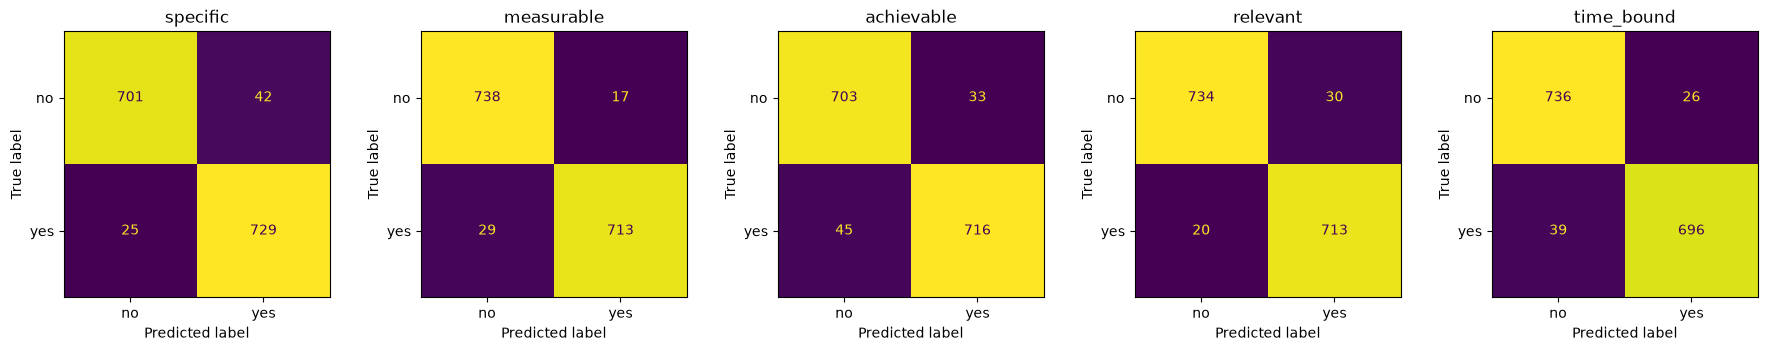

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, c in zip(axes, CRITERIA):
    ConfusionMatrixDisplay.from_predictions(test_df[c], models[c].predict(test_df.text), ax=ax,
                                            colorbar=False, display_labels=["no", "yes"])
    ax.set_title(c)
plt.tight_layout()
plt.show()

### Is a single tree good enough?

5-fold cross-validated F1 for a decision tree vs. logistic regression vs. a
random forest (an ensemble of 200 trees).

In [7]:
sample = df.sample(3000, random_state=SEED)   # keeps this cell quick
comparison = pd.DataFrame({
    kind: {c: cross_val_score(make_model(kind), sample.text, sample[c], cv=5, scoring="f1").mean()
           for c in CRITERIA}
    for kind in ["tree", "logreg", "forest"]
})
comparison.round(3)

,tree,logreg,forest
specific,0.945,0.968,0.968
measurable,0.964,0.967,0.966
achievable,0.941,0.955,0.927
relevant,0.959,0.968,0.968
time_bound,0.956,0.972,0.971


## 4. Look inside the models

What did each tree learn? Feature importances first, then the actual rules.

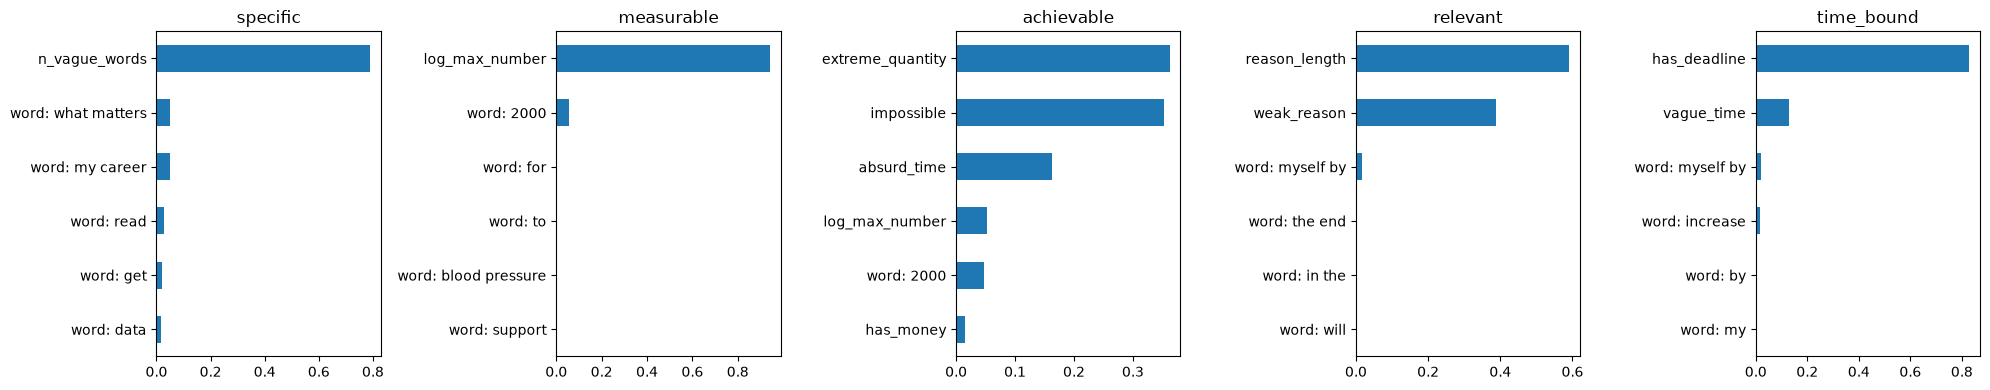

In [8]:
def feature_names(model):
    return model.named_steps["features"].get_feature_names_out()


fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, CRITERIA):
    tree = models[c].named_steps["clf"]
    imp = pd.Series(tree.feature_importances_, index=feature_names(models[c]))
    imp = imp[imp > 0].sort_values().tail(6)
    imp.index = [i.replace("hand__", "").replace("tfidf__", "word: ") for i in imp.index]
    imp.plot.barh(ax=ax, title=c)
plt.tight_layout()
plt.show()

In [9]:
c = "time_bound"
names = [n.replace("hand__", "").replace("tfidf__", "word: ") for n in feature_names(models[c])]
print(export_text(models[c].named_steps["clf"], feature_names=names, max_depth=3, decimals=2))

|--- has_deadline <= 0.50
|   |--- word: team <= 0.07
|   |   |--- word: my <= 0.14
|   |   |   |--- word: from <= 0.24
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- word: from >  0.24
|   |   |   |   |--- class: 0
|   |   |--- word: my >  0.14
|   |   |   |--- word: for <= 0.13
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- word: for >  0.13
|   |   |   |   |--- class: 0
|   |--- word: team >  0.07
|   |   |--- n_words <= 20.50
|   |   |   |--- class: 0
|   |   |--- n_words >  20.50
|   |   |   |--- class: 0
|--- has_deadline >  0.50
|   |--- vague_time <= 0.50
|   |   |--- word: myself by <= 0.23
|   |   |   |--- word: increase <= 0.26
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- word: increase >  0.26
|   |   |   |   |--- class: 0
|   |   |--- word: myself by >  0.23
|   |   |   |--- class: 0
|   |--- vague_time >  0.50
|   |   |--- word: my <= 0.10
|   |   |   |--- class: 0
|   |   |--- word: my >  0.10
|   |   |   |--- wo

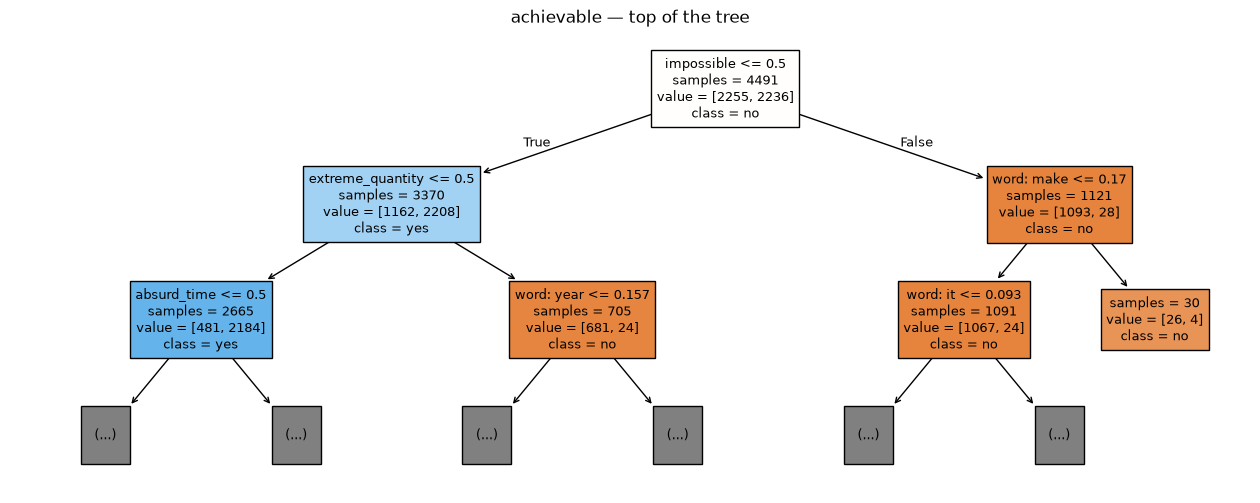

In [10]:
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(models["achievable"].named_steps["clf"], max_depth=2, feature_names=names,
          class_names=["no", "yes"], filled=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("achievable — top of the tree")
plt.show()

## 5. Reality check: hand-written goals

The test split above comes from the same generator, so it's an easy test.
These goals were written by hand in a different style, with my own labels.
Expect lower scores here — this is the honest number.

In [11]:
# text, S, M, A, R, T
HANDWRITTEN = [
    ("Run a half marathon in under 2 hours by October 2027 so I can join my running club's relay team.", 1, 1, 1, 1, 1),
    ("Get healthier.", 0, 0, 1, 0, 0),
    ("Increase our webshop conversion rate from 2% to 3% by the end of Q3 to hit the annual revenue target.", 1, 1, 1, 1, 1),
    ("Become a millionaire by next month.", 1, 1, 0, 0, 1),
    ("Read more books.", 0, 0, 1, 0, 0),
    ("Learn 50 new German words every week until December 2026 because I'm moving to Berlin for work.", 1, 1, 1, 1, 1),
    ("I want to lose 70 kg in two weeks.", 1, 1, 0, 0, 1),
    ("Someday I'd like to write a novel.", 1, 0, 1, 0, 0),
    ("Improve my coding skills.", 0, 0, 1, 0, 0),
    ("Save $3,000 for an emergency fund within 10 months so that I'm covered if my car breaks down.", 1, 1, 1, 1, 1),
    ("Be the best salesperson in the world.", 0, 0, 0, 0, 0),
    ("Cut my daily screen time to 2 hours by next month so I can sleep better.", 1, 1, 1, 1, 1),
    ("Get 10,000 new Instagram followers by tomorrow.", 1, 1, 0, 0, 1),
    ("Learn to play the guitar.", 1, 0, 1, 0, 0),
    ("Grow the business a lot.", 0, 0, 1, 0, 0),
    ("Pass 2 AWS certifications by March 2027 to qualify for the cloud engineer role.", 1, 1, 1, 1, 1),
    ("Do better at work eventually.", 0, 0, 1, 0, 0),
    ("Sign 5 new clients this quarter.", 1, 1, 1, 0, 1),
    ("Reduce customer churn by 15% within six months to stabilize recurring revenue.", 1, 1, 1, 1, 1),
    ("Learn 8 languages fluently by next summer.", 1, 1, 0, 0, 1),
    ("Be happier so that my family enjoys spending time with me.", 0, 0, 1, 1, 0),
    ("Publish 4 blog posts per month for my consulting business to attract new leads.", 1, 1, 1, 1, 0),
    ("Pay off my $8,000 student loan by December 2027.", 1, 1, 1, 0, 1),
]
hand = pd.DataFrame(HANDWRITTEN, columns=["text", *CRITERIA])
for c in CRITERIA:
    hand[f"{c}_pred"] = models[c].predict(hand.text)

scores = pd.DataFrame({c: {"accuracy": accuracy_score(hand[c], hand[f"{c}_pred"])} for c in CRITERIA}).T
display(scores.round(2))


def mark(row):
    return " ".join(
        ("✅" if row[f"{c}_pred"] else "❌") + ("" if row[c] == row[f"{c}_pred"] else "⚠️") for c in CRITERIA)


hand.assign(**{"S M A R T  (⚠️ = disagrees with my label)": hand.apply(mark, axis=1)})[
    ["text", "S M A R T  (⚠️ = disagrees with my label)"]]

,accuracy
specific,0.78
measurable,0.87
achievable,0.87
relevant,0.87
time_bound,1.00


,text,S M A R T (⚠️ = disagrees with my label)
0,Run a half marathon in under 2 hours by October 2027 so I can join my running club's relay team.,✅ ❌⚠️ ✅ ✅ ✅
1,Get healthier.,❌ ❌ ✅ ❌ ❌
2,Increase our webshop conversion rate from 2% to 3% by the end of Q3 to hit the annual revenue target.,✅ ✅ ✅ ✅ ✅
3,Become a millionaire by next month.,✅ ❌⚠️ ✅⚠️ ❌ ✅
4,Read more books.,✅⚠️ ❌ ✅ ❌ ❌
5,Learn 50 new German words every week until December 2026 because I'm moving to Berlin for work.,✅ ✅ ❌⚠️ ✅ ✅
6,I want to lose 70 kg in two weeks.,✅ ✅ ❌ ❌ ✅
7,Someday I'd like to write a novel.,✅ ❌ ✅ ❌ ❌
8,Improve my coding skills.,✅⚠️ ❌ ✅ ❌ ❌
9,"Save $3,000 for an emergency fund within 10 months so that I'm covered if my car breaks down.",✅ ✅ ✅ ✅ ✅


## 6. Try it yourself

`check_goal` runs all five models and prints a verdict with the model's
confidence (the share of training goals in that tree leaf that met the criterion).

In [12]:
HINTS = {
    "specific": "Name the concrete action or outcome (what exactly will change?).",
    "measurable": "Add a number: how much / how many / what %?",
    "achievable": "The target or deadline looks unrealistic — scale it down or give it more time.",
    "relevant": "Say why it matters: '... so that I can ...' / '... to support ...'.",
    "time_bound": "Add a deadline: 'by 30 June 2027', 'within 3 months'.",
}


def check_goal(goal: str) -> pd.DataFrame:
    rows = []
    for c in CRITERIA:
        p = models[c].predict_proba([goal])[0][1]
        rows.append({"criterion": c, "ok": "✅" if p >= 0.5 else "❌", "confidence (yes)": round(p, 2),
                     "hint": "" if p >= 0.5 else HINTS[c]})
    result = pd.DataFrame(rows).set_index("criterion")
    passed = (result.ok == "✅").sum()
    print(f"{goal!r}\n→ {passed}/5 criteria met" + (" — SMART! 🎯" if passed == 5 else ""))
    return result


check_goal("Get fit.")

'Get fit.'
→ 1/5 criteria met


,ok,confidence (yes),hint
criterion,,,
specific,❌,0.05,Name the concrete action or outcome (what exactly will change?).
measurable,❌,0.03,Add a number: how much / how many / what %?
achievable,✅,0.97,
relevant,❌,0.02,Say why it matters: '... so that I can ...' / '... to support ...'.
time_bound,❌,0.01,"Add a deadline: 'by 30 June 2027', 'within 3 months'."


In [13]:
check_goal("Run 10 km without stopping by 30 June 2027 so I can join the company running team.")

'Run 10 km without stopping by 30 June 2027 so I can join the company running team.'
→ 5/5 criteria met — SMART! 🎯


,ok,confidence (yes),hint
criterion,,,
specific,✅,0.97,
measurable,✅,0.98,
achievable,✅,0.97,
relevant,✅,0.97,
time_bound,✅,0.97,


In [14]:
# ✍️ put your own goal here
check_goal("I want to learn Python")

'I want to learn Python'
→ 2/5 criteria met


,ok,confidence (yes),hint
criterion,,,
specific,✅,0.97,
measurable,❌,0.03,Add a number: how much / how many / what %?
achievable,✅,0.97,
relevant,❌,0.02,Say why it matters: '... so that I can ...' / '... to support ...'.
time_bound,❌,0.01,"Add a deadline: 'by 30 June 2027', 'within 3 months'."
